# Where does gene-level upstream specificity come from?

One figure, four panels, one argument:

| panel | question | answer |
|---|---|---|
| **A** | **which model?** C3P embedding vs Evo-1 scoring vs Evo-1 embedding, 300 bp | only the contrastively-trained model retrieves the cognate upstream |
| **B** | **how much sequence?** C3P as the upstream is truncated toward the start codon | specificity needs ≳100–200 bp |
| **C** | schematic of the windows used in D | — |
| **D** | **which part?** windows at *matched width*, so only position changes | the 50 bp on the start codon carry almost nothing; signal peaks just behind it |

Metric throughout: **rank of the true upstream among 100 candidates** (1 = correct, chance
median 50.5), averaged over the 20 retrieval repeats → one paired observation per gene.
*E. coli* only.

Panels A–B use the length sweep (all 727 E. coli genes); panels C–D the window sweep
(design `d200`, the 409 genes with a ≥200 bp flank, where every window is fully defined —
the flanks are not all 300 bp, median ≈213 bp, so a subset is required for a paired test).

**Caveat to carry into the caption:** C3P was trained on windows anchored at the start
codon, so a −200..−100 window is presented to the encoder in the positional frame of a
−100..0 window. Every window in D shares that frame, so the comparisons are internally
controlled — but none of them is the model reading the distal region *in situ*.

Outputs → `results/cds_upstream_retrieval/fig_upstream_specificity.{pdf,png}`

## Setup

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import wilcoxon

ROOT = Path.cwd()
while not (ROOT / "data" / "cds_upstream_retrieval").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "cds_upstream_retrieval"
OUT_DIR = ROOT / "results" / "cds_upstream_retrieval"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(ROOT)

${ICBINB_ROOT}


### Configuration

In [2]:
SPECIES = "Escherichia coli"
PANEL_A_LENGTH = 300                  # full window for the model comparison
PANEL_B_LENGTHS = [200, 100, 50]      # truncation sweep; add 300 for the full window
WINDOW_DESIGN = "d200"                # window sweep design: genes with >= 200 bp flank
N_CANDIDATES = 100
CHANCE_MEDIAN = (N_CANDIDATES + 1) / 2
SEED = 20260803                       # jitter only
MEDIAN_TSS = -45                      # median E. coli 5'UTR, from the RegulonDB overlay

MODELS = [
    # key,     file,                        metric, label,              colour
    ("c3p",   "c3p_length_ranks.parquet",   None,   "C3P\nembedding",   "#2166AC"),
    ("evo_s", "evo8k_score_ranks.parquet",  "cds",  "Evo-1\nscoring",   "#1B7837"),
    ("evo_e", "evo8k_embed_ranks.parquet",  None,   "Evo-1\nembedding", "#762A83"),
]

# window name -> (distal edge, proximal edge, x position in D, series)
# "proximal" windows are anchored at the start codon; "distal" ones have the 50 bp
# next to the start codon deleted. Widths are matched across the two series at 100/150.
WINDOWS = {
    "prox50":  (50, 0, 1.00, "proximal"),
    "prox100": (100, 0, 2.20, "proximal"),
    "dist100": (200, 100, 2.90, "distal"),
    "prox150": (150, 0, 4.10, "proximal"),
    "dist150": (200, 50, 4.80, "distal"),
    "full200": (200, 0, 6.00, "proximal"),
}
WIDTH_TICKS = [(1.00, "50"), (2.55, "100"), (4.45, "150"), (6.00, "200")]
SERIES_COLOR = {"proximal": "#2166AC", "distal": "#D95F02"}

INK = "#1a1a1a"
GREY = "#8C8C8C"
LEN_COLOR = {300: "#08306B", 200: "#2166AC", 100: "#6BAED6", 50: "#BDD7E7"}
LEN_TEXT = {300: "#08306B", 200: "#2166AC", 100: "#3182BD", 50: "#6BAED6"}
YMAX = 340.0                          # log headroom for the significance brackets

### Style — shared with the other ICBINB figures (thick axes, Arial, type-42 fonts)

In [3]:
def set_style() -> None:
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
        "mathtext.fontset": "dejavusans",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
        "figure.dpi": 110,
        "savefig.dpi": 400,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.25,
        "axes.linewidth": 2.2,
        "axes.edgecolor": INK,
        "xtick.major.width": 2.2,
        "ytick.major.width": 2.2,
        "xtick.minor.width": 1.3,
        "ytick.minor.width": 1.3,
        "xtick.major.size": 7.0,
        "ytick.major.size": 7.0,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.color": INK,
        "ytick.color": INK,
        "axes.labelcolor": INK,
        "text.color": INK,
        "axes.labelsize": 13,
        "axes.labelweight": "bold",
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "lines.solid_capstyle": "round",
    })

set_style()

## Data

Panel A restricts all three models to the genes they share (the Evo scoring run used a
150-gene subsample of the C3P set) so the model comparison is paired. Panel D restricts to
one window-sweep design for the same reason.

In [4]:
def per_gene(df: pd.DataFrame, **sel) -> pd.DataFrame:
    """Collapse the 20 retrieval repeats to one number per gene.

    Rows are (species, ..., gene_row, rep, rank) with rank 1 = the true upstream was
    the top hit of 100. Averaging over repeats removes decoy-draw noise and leaves one
    paired observation per gene -- what the boxplots and the Wilcoxon tests use.
    """
    sub = df[df["species"] == SPECIES]
    for col, val in sel.items():
        if val is not None:
            sub = sub[sub[col] == val]
    return sub.groupby("gene_row")["rank"].agg(mean_rank="mean",
                                               top1=lambda s: (s == 1).mean())


def load(data_dir: Path):
    raw = {k: pd.read_parquet(data_dir / f) for k, f, _, _, _ in MODELS}

    # A: all three models on the genes they share (the Evo scoring run used a
    # 150-gene subsample of the C3P set), so the comparison is properly paired
    panel_a = {k: per_gene(raw[k], length=PANEL_A_LENGTH, metric=m)
               for k, _, m, _, _ in MODELS}
    shared = sorted(set.intersection(*(set(t.index) for t in panel_a.values())))
    panel_a = {k: t.loc[shared] for k, t in panel_a.items()}

    # B: C3P truncation sweep, all E. coli genes
    panel_b = {L: per_gene(raw["c3p"], length=L) for L in PANEL_B_LENGTHS}

    # D: C3P window sweep, one design so every window is defined for every gene
    win = pd.read_parquet(data_dir / "c3p_window_ranks.parquet")
    win = win[win["design"] == WINDOW_DESIGN]
    panel_d = {name: per_gene(win, window=name) for name in WINDOWS}
    return panel_a, panel_b, panel_d, shared

In [5]:
panel_a, panel_b, panel_d, shared = load(DATA_DIR)

summary = pd.DataFrame(
    [dict(panel="A", condition=lab.replace("\n", " "), n=len(shared),
          median_rank=panel_a[k]["mean_rank"].median(), top1_pct=panel_a[k]["top1"].mean() * 100)
     for k, _, _, lab, _ in MODELS]
    + [dict(panel="B", condition=f"C3P {L} bp (truncated)", n=len(panel_b[L]),
            median_rank=panel_b[L]["mean_rank"].median(), top1_pct=panel_b[L]["top1"].mean() * 100)
       for L in PANEL_B_LENGTHS]
    + [dict(panel="D", condition=f"{name} (-{b}..-{a})", n=len(panel_d[name]),
            median_rank=panel_d[name]["mean_rank"].median(),
            top1_pct=panel_d[name]["top1"].mean() * 100)
       for name, (b, a, _, _) in WINDOWS.items()])
summary.round(2)

,panel,condition,n,median_rank,top1_pct
0,A,C3P embedding,150,1.00,87.77
1,A,Evo-1 scoring,150,13.88,15.57
2,A,Evo-1 embedding,150,42.18,0.87
3,B,C3P 200 bp (truncated),727,1.00,84.87
4,B,C3P 100 bp (truncated),727,1.10,61.31
5,B,C3P 50 bp (truncated),727,23.10,11.28
6,D,prox50 (-50..-0),409,26.45,7.63
7,D,prox100 (-100..-0),409,1.70,49.83
8,D,dist100 (-200..-100),409,5.25,35.70
9,D,prox150 (-150..-0),409,1.00,73.99


## Drawing helpers

In [6]:
def stars(p: float) -> str:
    return ("****" if p < 1e-4 else "***" if p < 1e-3 else
            "**" if p < 1e-2 else "*" if p < 0.05 else "n.s.")


def boxes(ax, positions, values, colors, width=0.56):
    """Thick-lined boxplot with the per-gene points jittered on top."""
    bp = ax.boxplot(
        values, positions=positions, widths=width, patch_artist=True, showfliers=False,
        medianprops=dict(color=INK, lw=3.0, solid_capstyle="butt"),
        whiskerprops=dict(color=INK, lw=2.0), capprops=dict(color=INK, lw=2.0),
        boxprops=dict(lw=2.0, edgecolor=INK), zorder=3)
    for patch, col in zip(bp["boxes"], colors):
        patch.set_facecolor(col)
        patch.set_alpha(0.55)
    rng = np.random.default_rng(SEED)
    for x, v, col in zip(positions, values, colors):
        jx = x + rng.uniform(-width / 3, width / 3, size=len(v))
        ax.scatter(jx, v, s=7, color=col, alpha=0.25, linewidths=0, zorder=2,
                   rasterized=True)


def rank_axis(ax, chance_side="left") -> None:
    ax.set_yscale("log")
    ax.set_ylim(0.80, YMAX)
    ax.set_yticks([1, 2, 5, 10, 20, 50, 100])
    ax.set_yticklabels(["1", "2", "5", "10", "20", "50", "100"])
    ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.axhline(CHANCE_MEDIAN, ls=(0, (5, 4)), lw=2.0, color=GREY, zorder=1)
    x, ha = (0.015, "left") if chance_side == "left" else (0.985, "right")
    ax.text(x, CHANCE_MEDIAN * 1.09, "chance", transform=ax.get_yaxis_transform(),
            ha=ha, va="bottom", fontsize=10.5, color=GREY)
    ax.grid(axis="y", lw=0.8, color="#E6E6E6", zorder=0)
    ax.set_ylabel("Rank of the true upstream\n(1 of 100 candidates)", labelpad=26)
    # "better" pointing down the rank axis, in the gutter left of the y label
    ax.annotate("", xy=(-0.105, 0.30), xytext=(-0.105, 0.66), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=2.0, color=GREY))
    ax.text(-0.135, 0.48, "better", rotation=90, va="center", ha="center",
            fontsize=10.5, color=GREY, transform=ax.transAxes)


def top1_row(ax, xs, tops, colors, y) -> None:
    tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for x, t, col in zip(xs, tops, colors):
        ax.text(x, y, f"{t:.0f}%", transform=tr, ha="center", va="top",
                fontsize=11.5, fontweight="bold", color=col, clip_on=False)


def panel_label(ax, letter, dx=-0.17, dy=1.13) -> None:
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=19, fontweight="bold",
            va="top", ha="left", color=INK)


def sig_bracket(ax, x1, x2, y, text, h=1.13) -> None:
    ax.plot([x1, x1, x2, x2], [y, y * h, y * h, y], lw=1.8, color=INK, clip_on=False)
    ax.text((x1 + x2) / 2, y * h * 1.03, text, ha="center", va="bottom", fontsize=12,
            color=INK, clip_on=False)

## Panels

Significance is a one-sided paired Wilcoxon signed-rank test on the per-gene mean ranks
(A: C3P vs each Evo readout; B: 200 bp vs each truncation; D: the two width-matched
proximal-vs-distal contrasts). `**** = p < 1e-4`.

In [7]:
def draw_models(ax, panel_a, n_shared, tests):
    keys = [k for k, *_ in MODELS]
    colors = [c for *_, c in MODELS]
    boxes(ax, [1, 2, 3], [panel_a[k]["mean_rank"].to_numpy() for k in keys], colors)
    rank_axis(ax)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels([lab for *_, lab, _ in MODELS])
    ax.set_title(f"Which model?  $\\it{{E.\\ coli}}$, {PANEL_A_LENGTH} bp upstream\n"
                 f"n = {n_shared} genes shared by all three runs", fontsize=12, pad=38)
    top1_row(ax, [1, 2, 3], [panel_a[k]["top1"].mean() * 100 for k in keys],
             colors, y=-0.165)
    ax.text(0.5, -0.245, "top-1 retrieval accuracy", transform=ax.transAxes,
            ha="center", va="top", fontsize=11, color=GREY)
    for k, y in zip(keys[1:], (122, 205)):
        stat, p = wilcoxon(panel_a["c3p"]["mean_rank"], panel_a[k]["mean_rank"],
                           alternative="less", zero_method="wilcox")
        tests.append(dict(panel="A", comparison=f"c3p_vs_{k}", n=n_shared,
                          wilcoxon_stat=float(stat), p_one_sided=float(p), stars=stars(p)))
        sig_bracket(ax, 1, 2 if y == 122 else 3, y, stars(p))
    panel_label(ax, "A")


def draw_lengths(ax, panel_b, tests):
    xs = list(range(1, len(PANEL_B_LENGTHS) + 1))
    cols = [LEN_COLOR[L] for L in PANEL_B_LENGTHS]
    boxes(ax, xs, [panel_b[L]["mean_rank"].to_numpy() for L in PANEL_B_LENGTHS], cols)
    rank_axis(ax)
    ax.set_xticks(xs)
    ax.set_xticklabels([str(L) for L in PANEL_B_LENGTHS])
    ax.set_xlabel("Upstream retained (bp), truncated toward the start codon", labelpad=34)
    n_b = len(panel_b[PANEL_B_LENGTHS[0]])
    ax.set_title(f"How much sequence?  C3P embedding\nn = {n_b} $\\it{{E.\\ coli}}$ genes",
                 fontsize=12, pad=38)
    top1_row(ax, xs, [panel_b[L]["top1"].mean() * 100 for L in PANEL_B_LENGTHS],
             [LEN_TEXT[L] for L in PANEL_B_LENGTHS], y=-0.115)
    ax.annotate("", xy=(0.95, 1.045), xytext=(0.05, 1.045), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color=INK))
    ax.text(0.5, 1.065, "shorter upstream", transform=ax.transAxes, ha="center",
            va="bottom", fontsize=11, color=INK)
    ref = PANEL_B_LENGTHS[0]
    for i, L in enumerate(PANEL_B_LENGTHS[1:], start=1):
        m = panel_b[ref].join(panel_b[L], lsuffix="_a", rsuffix="_b")
        stat, p = wilcoxon(m["mean_rank_a"], m["mean_rank_b"], alternative="less",
                           zero_method="wilcox")
        tests.append(dict(panel="B", comparison=f"c3p_{ref}bp_vs_{L}bp", n=len(m),
                          wilcoxon_stat=float(stat), p_one_sided=float(p), stars=stars(p)))
        sig_bracket(ax, 1, i + 1, 122 if i == 1 else 205, stars(p))
    panel_label(ax, "B")


def draw_schematic(ax):
    """Panel C -- the windows of panel D drawn on the upstream, to scale."""
    ax.set_xlim(-215, 38)
    ax.set_ylim(-0.4, 6.9)
    ax.axis("off")

    # the upstream ruler + the CDS
    ax.add_patch(Rectangle((-200, 6.0), 200, 0.5, facecolor="#EDEDED",
                           edgecolor=INK, lw=1.6, zorder=2))
    ax.add_patch(Rectangle((2, 5.95), 32, 0.6, facecolor="#4D4D4D", edgecolor=INK,
                           lw=1.6, zorder=2))
    ax.text(18, 6.25, "CDS", ha="center", va="center", fontsize=10.5,
            color="white", fontweight="bold", zorder=3)
    ax.text(0, 5.55, "ATG", ha="center", va="top", fontsize=10, color=INK,
            fontweight="bold")
    for x in (-200, -150, -100, -50):
        ax.plot([x, x], [5.9, 6.0], lw=1.6, color=INK, zorder=3)
        ax.text(x, 5.62, str(x), ha="center", va="top", fontsize=10, color=GREY)
    ax.text(-100, 6.85, "upstream (bp relative to the start codon)", ha="center",
            va="bottom", fontsize=11, color=INK)

    # median TSS, from the RegulonDB overlay -- everything right of it is 5'UTR
    ax.plot([MEDIAN_TSS, MEDIAN_TSS], [0.15, 5.9], ls=(0, (3, 3)), lw=1.6,
            color="#B2182B", zorder=1)
    ax.text(MEDIAN_TSS, 0.02, "median TSS (5$'$UTR = 45 bp)", ha="center", va="top",
            fontsize=9.5, color="#B2182B")

    # one row per window, in panel-D order
    for i, (name, (b, a, _, series)) in enumerate(WINDOWS.items()):
        y = 4.9 - i * 0.86
        ax.add_patch(Rectangle((-b, y), b - a, 0.46, facecolor=SERIES_COLOR[series],
                               alpha=0.75, edgecolor=INK, lw=1.5, zorder=2))
        ax.text(-207, y + 0.23, name, ha="right", va="center", fontsize=10.5,
                color=SERIES_COLOR[series], fontweight="bold")
        ax.text(6, y + 0.23, f"{b - a} bp", ha="left", va="center", fontsize=10,
                color=GREY)
    panel_label(ax, "C", dx=-0.15, dy=1.02)


def draw_windows(ax, panel_d, tests):
    names = list(WINDOWS)
    pos = [WINDOWS[n][2] for n in names]
    cols = [SERIES_COLOR[WINDOWS[n][3]] for n in names]
    boxes(ax, pos, [panel_d[n]["mean_rank"].to_numpy() for n in names], cols, width=0.52)
    rank_axis(ax, chance_side="right")
    ax.set_xlim(0.35, 6.65)
    ax.set_xticks([x for x, _ in WIDTH_TICKS])
    ax.set_xticklabels([lab for _, lab in WIDTH_TICKS])
    ax.set_xlabel("Window width (bp) — same width, different position", labelpad=34)
    n_d = len(panel_d["prox100"])
    ax.set_title("Which part?  C3P embedding, matched-width windows\n"
                 f"n = {n_d} $\\it{{E.\\ coli}}$ genes with a $\\geq$200 bp upstream",
                 fontsize=12, pad=38)
    top1_row(ax, pos, [panel_d[n]["top1"].mean() * 100 for n in names], cols, y=-0.115)
    ax.legend(handles=[
        Line2D([0], [0], marker="s", ls="", ms=11, color=SERIES_COLOR["proximal"],
               alpha=0.75, label="anchored at the start codon"),
        Line2D([0], [0], marker="s", ls="", ms=11, color=SERIES_COLOR["distal"],
               alpha=0.75, label="proximal 50 bp deleted")],
        loc="lower left", bbox_to_anchor=(-0.02, 1.005), ncol=2, handletextpad=0.5,
        columnspacing=1.6)
    # the two width-matched contrasts
    for (pn, dn), y in zip((("prox100", "dist100"), ("prox150", "dist150")), (122, 205)):
        m = panel_d[pn].join(panel_d[dn], lsuffix="_p", rsuffix="_d")
        stat, p = wilcoxon(m["mean_rank_p"], m["mean_rank_d"], alternative="less",
                           zero_method="wilcox")
        tests.append(dict(panel="D", comparison=f"{pn}_vs_{dn}", n=len(m),
                          wilcoxon_stat=float(stat), p_one_sided=float(p), stars=stars(p)))
        sig_bracket(ax, WINDOWS[pn][2], WINDOWS[dn][2], y, stars(p))
    panel_label(ax, "D")

## The figure

In [8]:
def make_figure(panel_a, panel_b, panel_d, n_shared):
    set_style()
    fig, axes = plt.subplots(2, 2, figsize=(13.0, 10.6))
    tests: list[dict] = []
    draw_models(axes[0, 0], panel_a, n_shared, tests)
    draw_lengths(axes[0, 1], panel_b, tests)
    draw_schematic(axes[1, 0])
    draw_windows(axes[1, 1], panel_d, tests)
    fig.tight_layout(w_pad=5.0, h_pad=1.6)
    return fig, pd.DataFrame(tests)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


wrote ${ICBINB_ROOT}/results/cds_upstream_retrieval/fig_upstream_specificity.pdf and .png


,panel,comparison,n,wilcoxon_stat,p_one_sided,stars
0,A,c3p_vs_evo_s,150,150.0,6.080864e-23,****
1,A,c3p_vs_evo_e,150,13.0,2.182838e-26,****
2,B,c3p_200bp_vs_100bp,727,5433.5,4.658335e-50,****
3,B,c3p_200bp_vs_50bp,727,1352.0,6.743325e-113,****
4,D,prox100_vs_dist100,409,21534.5,9.969342e-09,****
5,D,prox150_vs_dist150,409,7353.0,2.621001e-05,****


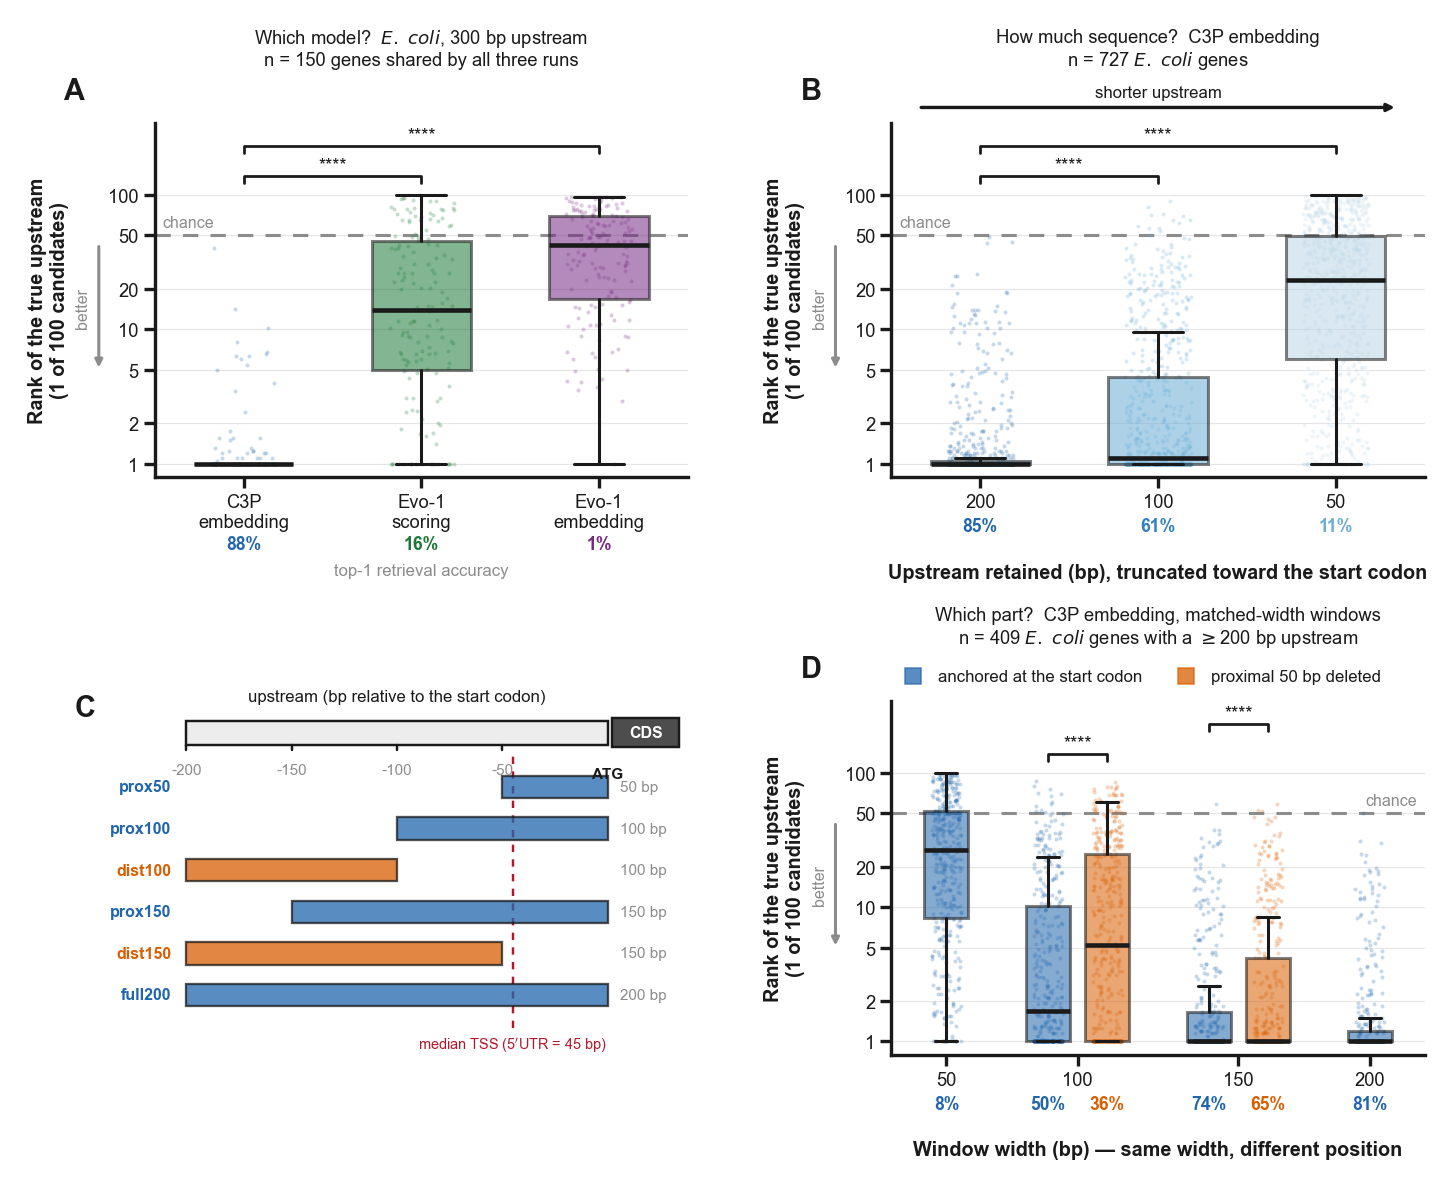

In [9]:
fig, tests = make_figure(panel_a, panel_b, panel_d, len(shared))
for ext in ("pdf", "png"):
    fig.savefig(OUT_DIR / f"fig_upstream_specificity.{ext}")
summary.to_csv(OUT_DIR / "fig_upstream_specificity_summary.csv", index=False)
tests.to_csv(OUT_DIR / "fig_upstream_specificity_stats.csv", index=False)
print(f"wrote {OUT_DIR}/fig_upstream_specificity.pdf and .png")
tests

## Read-out

**A — which model.** Only C3P, contrastively trained to align a protein with its own
upstream, retrieves the cognate upstream (top-1 88 %, median rank 1). Evo-1 likelihood
scoring is above chance but weak (16 %, median ≈14); Evo-1 mean-pooled embeddings are at
chance (1 %, median ≈42). A generative DNA LM does not link a coding region to its own
promoter for free.

**B — how much sequence.** Truncating toward the start codon costs little to 200 bp, some
at 100 bp, nearly everything at 50 bp (85 → 61 → 11 %).

**D — which part.** Held at matched width, the 50 bp abutting the start codon are almost
useless alone (8 % top-1, median rank 26) and deleting them costs only 81 → 65 %. But the
width-matched pairs still favour the proximal window (100 bp: 50 % vs 36 %; 150 bp: 74 % vs
65 %), so this is not a simple proximal/distal split. Reading the nested proximal series as
marginal gains — 50 bp 8 %, +(−100..−50) → 50 %, +(−150..−100) → 74 %, +(−200..−150) → 81 %
— the band doing the heavy lifting is **−100..−50**, immediately behind the median TSS and
matching the −62 peak from the independent single-6 bp occlusion run.

So the signal is centred just upstream of the TSS and distributed outward, and it is
absent from the SD/RBS neighbourhood next to the start codon.